In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from pathlib import Path

In [2]:
base_dir = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
arff_path = base_dir / "mnist_784.arff"
data, meta = arff.loadarff(arff_path)

pixel_names = meta.names()[:-1]
target_name = meta.names()[-1]

X = np.column_stack([data[col] for col in pixel_names]).astype(np.float32) / 255.0
y = np.array([int(val.decode("utf-8")) for val in data[target_name]], dtype=np.int32)

# Shuffle dataset
perm = np.random.permutation(len(X))
X = X[perm]
y = y[perm]

n = len(X)
split_mark = int(n * 0.8)

x_train = X[:split_mark].T  # shape: (784, 56000)
y_train = y[:split_mark]  # shape: (56000)

x_test = X[split_mark:].T  # shape: (784, 14000)
y_test = y[split_mark:]  # shape: (14000)

In [20]:
#BASIC FUNCTIONS

#initialize parameters
def init_params():
    hidden_layers= 10
    W1 = np.random.rand(hidden_layers,784) - 0.5
    b1 = np.random.rand(hidden_layers, 1) - 0.5
    W2 = np.random.rand(10, hidden_layers) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    return W1, b1, W2, b2

#initialize actvation functions
def ReLU(Z):
    return np.maximum(Z,0)

def softmax(Z):
    expZ = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return expZ / np.sum(expZ, axis=0, keepdims=True)

#forward pass
def forward_pass(W1,b1,W2,b2,X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1,A1,Z2,A2

#cross entropy loss
def get_loss(A2, Y):
    m = Y.shape[0]
    one_hot_Y = one_hot(Y)
    log_probs = np.log(A2 + 1e-8)
    loss = -np.sum(one_hot_Y * log_probs) / m
    return loss

def ReLU_deriv(Z):
  return Z>0

#takes results and prepares them to compare with solutions. e.g: 2 -> [0,0,1,0,0,0,0,0,0]
def one_hot(Y): 
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y

def backpropogation(Z1,A1,Z2,A2,W1,W2,X,Y):
    m = X.shape[1]
    one_hot_Y = one_hot(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = (1 / m) * dZ2.dot(A1.T)
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T.dot(dZ2) * ReLU_deriv(Z1)
    dW1 = (1 / m) * dZ1.dot(X.T)
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, db1, dW2, db2

def update_params(W1,b1,W2,b2,dW1,db1,dW2,db2,lr):
    W1 = W1 - lr*dW1
    b1 = b1 - lr*db1
    W2 = W2 - lr*dW2
    b2 = b2 - lr*db2
    return W1, b1, W2, b2

def get_accuracy(predictions, y):
    preds = np.asarray(predictions)
    targets = np.asarray(y)

    pred_classes = np.argmax(preds, axis=1)
    return float(np.mean(pred_classes == targets))
    

In [4]:
#main function
def gradient_descent(X, Y, alpha, iterations):
    W1, b1, W2, b2 = init_params()
    losses = []
    for i in range(iterations+1):
        Z1, A1, Z2, A2 = forward_pass(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = backpropogation(Z1, A1, Z2, A2, W1, W2, X, Y)
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)
        if i % 100 == 0 or i == iterations:
            acc = get_accuracy(A2.T, Y)
            loss = get_loss(A2, Y)
            print(f"Iteration {i} — Loss: {loss:.4f}, Accuracy: {acc:.4f}")
            losses.append(loss)
    return W1, b1, W2, b2,losses

In [5]:
#MAIN CALL
W1, b1, W2, b2,losses = gradient_descent(x_train, y_train, 0.25, 2000)

Iteration 0 — Loss: 3.3253, Accuracy: 0.1301
Iteration 100 — Loss: 0.6181, Accuracy: 0.8090
Iteration 200 — Loss: 0.4638, Accuracy: 0.8606
Iteration 300 — Loss: 0.4070, Accuracy: 0.8799
Iteration 400 — Loss: 0.3740, Accuracy: 0.8904
Iteration 500 — Loss: 0.3513, Accuracy: 0.8970
Iteration 600 — Loss: 0.3339, Accuracy: 0.9026
Iteration 700 — Loss: 0.3198, Accuracy: 0.9072
Iteration 800 — Loss: 0.3080, Accuracy: 0.9112
Iteration 900 — Loss: 0.2979, Accuracy: 0.9143
Iteration 1000 — Loss: 0.2889, Accuracy: 0.9170
Iteration 1100 — Loss: 0.2811, Accuracy: 0.9193
Iteration 1200 — Loss: 0.2741, Accuracy: 0.9214
Iteration 1300 — Loss: 0.2679, Accuracy: 0.9234
Iteration 1400 — Loss: 0.2623, Accuracy: 0.9249
Iteration 1500 — Loss: 0.2572, Accuracy: 0.9263
Iteration 1600 — Loss: 0.2526, Accuracy: 0.9283
Iteration 1700 — Loss: 0.2484, Accuracy: 0.9293
Iteration 1800 — Loss: 0.2446, Accuracy: 0.9304
Iteration 1900 — Loss: 0.2410, Accuracy: 0.9317
Iteration 2000 — Loss: 0.2377, Accuracy: 0.9328


In [7]:
#Evaluating functions
def evaluate_test(x, y, W1, b1, W2, b2):
    Z1,A1,Z2,probs= forward_pass(W1,b1,W2,b2,x)

    pred_classes = np.argmax(probs, axis=0)
    true_classes = np.asarray(y)

    correct = int(np.sum(pred_classes == true_classes))
    total = len(true_classes)
    accuracy = correct / total

    print(f"Accuracy: {accuracy:.2%} ({correct}/{total} correct)")

    #Per-digit breakdown (0 through 9)
    for digit in range(10):
        mask = true_classes == digit
        digit_total = int(np.sum(mask))
        if digit_total > 0:
            digit_correct = int(np.sum(pred_classes[mask] == digit))
            print(
                f"  Digit {digit}: {digit_correct / digit_total:6.2%}"
                f" ({digit_correct}/{digit_total})"
            )

def predict_one(index, x_test, y_test, W1, b1, W2, b2, show_image=True):
    x_sample = x_test[:, index : index + 1]
    true_label = int(y_test[index])

    Z1,A1,Z2,A2= forward_pass(W1,b1,W2,b2,x_sample)
  
    pred_label = int(np.argmax(A2, axis=0)[0])
    confidence = float(np.max(A2))

    print(f"Index:      {index} / {len(y_test)}")
    print(f"Prediction: {pred_label} (confidence: {confidence:.2%})")
    print(f"Actual:     {true_label}")
    print(f"Result:     {'CORRECT' if pred_label == true_label else 'WRONG'}")

    if show_image:
        image = x_sample.reshape(28, 28)
        plt.figure(figsize=(3, 3))
        plt.imshow(image, cmap="gray")
        plt.title(f"Pred: {pred_label} | True: {true_label}")
        plt.axis("off")
        plt.show()

In [18]:
evaluate_test(x_test, y_test, W1, b1, W2, b2)

Accuracy: 92.91% (13007/14000 correct)
  Digit 0: 96.75% (1339/1384)
  Digit 1: 97.15% (1533/1578)
  Digit 2: 91.44% (1303/1425)
  Digit 3: 90.11% (1284/1425)
  Digit 4: 93.91% (1327/1413)
  Digit 5: 88.93% (1117/1256)
  Digit 6: 95.22% (1314/1380)
  Digit 7: 94.11% (1326/1409)
  Digit 8: 90.11% (1221/1355)
  Digit 9: 90.40% (1243/1375)


In [19]:
evaluate_test(X.T, y, W1, b1, W2, b2)

Accuracy: 92.51% (64758/70000 correct)
  Digit 0: 95.86% (6617/6903)
  Digit 1: 97.05% (7645/7877)
  Digit 2: 90.69% (6339/6990)
  Digit 3: 89.90% (6420/7141)
  Digit 4: 93.38% (6372/6824)
  Digit 5: 88.48% (5586/6313)
  Digit 6: 95.06% (6536/6876)
  Digit 7: 94.04% (6858/7293)
  Digit 8: 89.42% (6103/6825)
  Digit 9: 90.28% (6282/6958)


Index:      12345 / 70000
Prediction: 3 (confidence: 99.19%)
Actual:     3
Result:     CORRECT


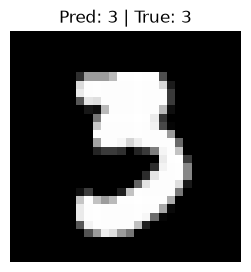

In [14]:
index= 12345
predict_one(index,X.T, y, W1, b1, W2, b2, True)

In [12]:
def save_weights(W1, b1, W2, b2):
    name = input("Enter a name for the weights file: ").strip()
    if not name:
        raise ValueError("Filename cannot be empty.")

    path = Path.cwd() / name
    if path.suffix != ".npz":
        path = path.with_suffix(".npz")

    np.savez(path, W1=W1, b1=b1, W2=W2, b2=b2)
    print(f"Saved to {path}")

def load_weights():
    folder = Path.cwd()
    npz_files = sorted(folder.glob("*.npz"))

    if not npz_files:
        raise FileNotFoundError(f"No .npz weight files found in {folder}")

    print("Available weight files:")
    for i, file in enumerate(npz_files, start=1):
        print(f"  {i}. {file.name}")
    name = input("Enter the name of the weights file to load: ").strip()
    if not name:
        raise ValueError("Filename cannot be empty.")

    path = Path.cwd() / name
    if not path.exists() and path.with_suffix(".npz").exists():
        path = path.with_suffix(".npz")
    elif not path.exists():
        raise FileNotFoundError(f"Could not find weights file at: {path}")

    with np.load(path) as data:
        W1 = data["W1"]
        b1 = data["b1"]
        W2 = data["W2"]
        b2 = data["b2"]

    print(f"Loaded from {path}")
    return W1, b1, W2, b2

In [15]:
save_weights(W1, b1, W2, b2)

Enter a name for the weights file:  93,1acc


Saved to /home/dlz/Documents/Code/MNIST_NeuralNetwork/93,1acc.npz


In [17]:
W1, b1, W2, b2= load_weights()

Available weight files:
  1. 90,4acc.npz
  2. 92,5acc.npz
  3. 93,1acc.npz


Enter the name of the weights file to load:  92,5acc


Loaded from /home/dlz/Documents/Code/MNIST_NeuralNetwork/92,5acc.npz
